## Parallelization

LangGraph에서 여러 노드를 **동시에** 실행하는 방법을 배운다.

In [1]:
import operator
import time
from typing import Annotated, TypedDict

from dotenv import load_dotenv
from IPython.display import Image, display
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field

load_dotenv()

MODEL_NAME = "gemini-3.6-flash"

### 병렬 처리가 필요한 이유

하나의 문서를 3개 관점(법률, 재무, 기술)으로 분석한다고 하자.

**순차 처리:**
```
법률 분석 (3초) → 재무 분석 (3초) → 기술 분석 (3초) = 총 9초
```

**병렬 처리:**
```
법률 분석 (3초) ─┐
재무 분석 (3초) ─┼→ 종합 = 총 3초 + α
기술 분석 (3초) ─┘
```

분석 관점이 서로 독립적이면 작업 간 의존성을 깨뜨리지 않고 병렬로 실행할 수 있다. 단, LLM의 응답 내용과 병렬 결과가 합쳐지는 순서는 실행할 때마다 달라질 수 있다. LangGraph는 이런 병렬 실행을 **그래프 구조**로 자연스럽게 표현한다.

### 기본 병렬 노드 (Fan-out / Fan-in)

하나의 노드 뒤에 여러 노드를 연결하면 LangGraph가 자동으로 **병렬 실행**한다.

```
START ─┬→ legal_analysis     ─┐
       ├→ financial_analysis ─┼→ summarize → END
       └→ technical_analysis ─┘
```

핵심: State에 `Annotated[list, operator.add]`를 사용해서 각 노드의 결과를 **하나의 리스트에 누적**한다.

In [ ]:
llm = ChatGoogleGenerativeAI(model=MODEL_NAME)


class AnalysisState(TypedDict):
    document: str
    analyses: Annotated[list, operator.add]  # 각 분석 결과가 누적됨
    summary: str


def legal_analysis(state: AnalysisState):
    result = llm.invoke(
        f"다음 문서를 법률 관점에서 핵심 리스크 2가지를 분석해줘. 간결하게.\n\n{state['document']}"
    )
    print("[legal_analysis] 완료")
    return {"analyses": [f"[법률] {result.text}"]}


def financial_analysis(state: AnalysisState):
    result = llm.invoke(
        f"다음 문서를 재무 관점에서 핵심 포인트 2가지를 분석해줘. 간결하게.\n\n{state['document']}"
    )
    print("[financial_analysis] 완료")
    return {"analyses": [f"[재무] {result.text}"]}


def technical_analysis(state: AnalysisState):
    result = llm.invoke(
        f"다음 문서를 기술 관점에서 핵심 포인트 2가지를 분석해줘. 간결하게.\n\n{state['document']}"
    )
    print("[technical_analysis] 완료")
    return {"analyses": [f"[기술] {result.text}"]}


def summarize(state: AnalysisState):
    all_analyses = "\n\n".join(state["analyses"])
    result = llm.invoke(
        f"다음 3가지 관점의 분석을 종합해서 3줄로 요약해줘:\n\n{all_analyses}"
    )
    return {"summary": result.text}

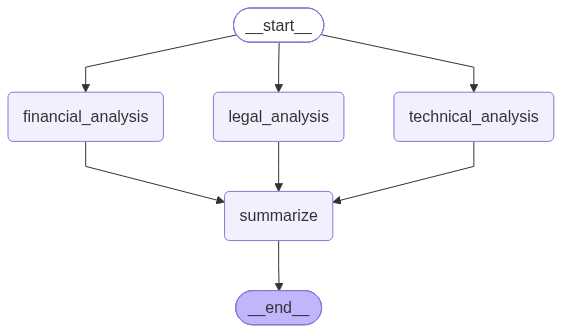

In [3]:
graph_builder = StateGraph(AnalysisState)

graph_builder.add_node("legal_analysis", legal_analysis)
graph_builder.add_node("financial_analysis", financial_analysis)
graph_builder.add_node("technical_analysis", technical_analysis)
graph_builder.add_node("summarize", summarize)

# Fan-out: START → 3개 분석 노드 (병렬)
graph_builder.add_edge(START, "legal_analysis")
graph_builder.add_edge(START, "financial_analysis")
graph_builder.add_edge(START, "technical_analysis")

# Fan-in: 3개 분석 노드가 모두 완료된 뒤 summarize 실행
graph_builder.add_edge(
    ["legal_analysis", "financial_analysis", "technical_analysis"],
    "summarize",
)
graph_builder.add_edge("summarize", END)

analysis_graph = graph_builder.compile()
display(Image(analysis_graph.get_graph().draw_mermaid_png()))

In [4]:
document = """AI 스타트업 A사가 시리즈B 투자 500억원을 유치했다.
핵심 기술은 자체 개발한 경량 LLM으로, 기존 모델 대비 추론 속도가 3배 빠르다.
다만 학습 데이터의 저작권 문제가 일부 제기되고 있으며,
현재 매출 대비 기업가치가 100배 수준이라는 지적도 있다.
올해 하반기 상용화를 목표로 하고 있다."""

start = time.perf_counter()
result = {"analyses": []}
for event in analysis_graph.stream(
    {"document": document}, stream_mode="updates"
):
    for node_name, update in event.items():
        print(f"[노드 완료] {node_name} -> {list(update.keys())}")
        if "analyses" in update:
            result["analyses"].extend(update["analyses"])
        if "summary" in update:
            result["summary"] = update["summary"]
elapsed = time.perf_counter() - start

print(f"\n소요 시간: {elapsed:.1f}초")
print(f"\n=== 분석 결과 ({len(result['analyses'])}개) ===")
for a in result["analyses"]:
    print(a)
    print()
print(f"=== 종합 ===")
print(result["summary"])

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.
Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.
Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


[technical_analysis] 완료
[노드 완료] technical_analysis -> ['analyses']
[financial_analysis] 완료
[노드 완료] financial_analysis -> ['analyses']
[legal_analysis] 완료
[노드 완료] legal_analysis -> ['analyses']
[노드 완료] summarize -> ['summary']

소요 시간: 16.3초

=== 분석 결과 (3개) ===
[기술] 기술 관점에서 분석한 핵심 포인트 2가지입니다.

1. **고효율 경량화 및 추론 최적화 기술 확보**
   * 자체 개발한 경량 LLM을 통해 기존 대비 **추론 속도를 3배 향상**시켜, 서비스 상용화 및 운용 비용(GPU 인프라 등) 절감 측면에서 기술적 경쟁력을 확보함.

2. **학습 데이터 파이프라인의 저작권 및 규제 리스크**
   * 모델 성능을 좌우하는 **학습 데이터의 저작권 문제**가 제기됨에 따라, 향후 데이터 재학습 필요성이나 기술적·법적 신뢰성 훼손으로 인한 서비스 차질 위험이 존재함.

[재무] 제시된 문서의 재무 관점 핵심 포인트 2가지입니다.

1. **대규모 유동성 확보 및 고평가(Overvaluation) 리스크**
   * 500억 원의 투자 유치로 개발 및 사업화를 위한 풍부한 현금을 확보했으나, 매출 대비 기업가치 100배(PSR 100배)는 시장의 기대감이 과도하게 반영된 수준으로 단기 실적 부담이 매우 큽니다.

2. **매출 창출을 통한 가치 정당화와 법적 우발부채 위험**
   * 하반기 상용화를 통해 고평가를 증명할 실질적 매출을 보여주어야 하나, 학습 데이터 저작권 문제는 향후 손해배상 청구나 영업 중지 등 재무적 손실(우발부채)을 일으킬 수 있는 주요 위험 요인입니다.

[법률] 제시된 문서를 바탕으로 한 법률 관점의 핵심 리스크 2가지는 다음과 같습니다.

**1. AI 학습 데이터의 저작권 침해 및 서비스 중단 리스크**
* **내용:** 

### 결과 순서가 필요할 때

병렬 노드의 결과는 어떤 노드가 먼저 끝나느냐에 따라 순서가 달라진다. 순서가 중요하면 결과에 **식별자를 포함**시키고 후처리에서 정렬하면 된다.

위 예제의 분석 노드를 수정해서, 결과를 `(순서, 내용)` 튜플로 반환하고 `summarize`에서 정렬하는 방식이다.

In [ ]:
class OrderedAnalysisState(TypedDict):
    document: str
    analyses: Annotated[list, operator.add]  # (순서, 내용) 튜플이 누적됨
    summary: str


def ordered_legal(state: OrderedAnalysisState):
    result = llm.invoke(
        f"다음 문서를 법률 관점에서 핵심 리스크 2가지를 분석해줘. 간결하게.\n\n{state['document']}"
    )
    return {"analyses": [(0, f"[법률] {result.text}")]}


def ordered_financial(state: OrderedAnalysisState):
    result = llm.invoke(
        f"다음 문서를 재무 관점에서 핵심 포인트 2가지를 분석해줘. 간결하게.\n\n{state['document']}"
    )
    return {"analyses": [(1, f"[재무] {result.text}")]}


def ordered_technical(state: OrderedAnalysisState):
    result = llm.invoke(
        f"다음 문서를 기술 관점에서 핵심 포인트 2가지를 분석해줘. 간결하게.\n\n{state['document']}"
    )
    return {"analyses": [(2, f"[기술] {result.text}")]}


def ordered_summarize(state: OrderedAnalysisState):
    # 순서대로 정렬
    sorted_analyses = sorted(state["analyses"], key=lambda x: x[0])
    print("정렬된 순서:")
    for order, content in sorted_analyses:
        print(f"  {order}: {content[:30]}...")

    all_analyses = "\n\n".join(content for _, content in sorted_analyses)
    result = llm.invoke(
        f"다음 3가지 관점의 분석을 종합해서 3줄로 요약해줘:\n\n{all_analyses}"
    )
    return {"summary": result.text}


graph_builder = StateGraph(OrderedAnalysisState)
graph_builder.add_node("legal", ordered_legal)
graph_builder.add_node("financial", ordered_financial)
graph_builder.add_node("technical", ordered_technical)
graph_builder.add_node("summarize", ordered_summarize)

graph_builder.add_edge(START, "legal")
graph_builder.add_edge(START, "financial")
graph_builder.add_edge(START, "technical")
graph_builder.add_edge(["legal", "financial", "technical"], "summarize")
graph_builder.add_edge("summarize", END)

ordered_graph = graph_builder.compile()

result = {"analyses": []}
for event in ordered_graph.stream(
    {"document": document}, stream_mode="updates"
):
    for node_name, update in event.items():
        print(f"[노드 완료] {node_name} -> {list(update.keys())}")
        if "analyses" in update:
            result["analyses"].extend(update["analyses"])
        if "summary" in update:
            result["summary"] = update["summary"]
print(f"\n=== 종합 ===")
print(result["summary"])

### Voting 패턴

하나의 질문에 대해 **여러 LLM 응답을 동시에 생성**하고, 그 중 최선의 답변을 선택하는 패턴이다.

```
START ─┬→ generate_1 ─┐
       ├→ generate_2 ─┼→ vote → END
       └→ generate_3 ─┘
```

같은 모델에 서로 다른 접근 방식의 프롬프트를 전달해 다양한 답변을 만들고, 그중 품질이 높은 답변을 선택한다. 서로 다른 Gemini 모델을 동시에 호출하는 방식도 가능하다. 평가(judge)용 LLM은 후보 생성과 평가 기준을 분리해 객관적으로 판단하도록 구성한다.

Voting 패턴은 마케팅 카피, 코드 생성, 번역처럼 결과의 품질 편차가 큰 작업에서 여러 후보를 비교할 때 활용할 수 있다.

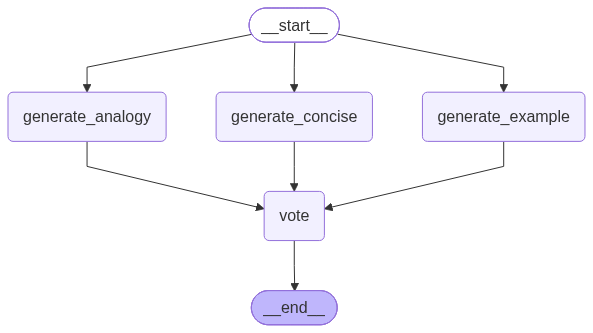

In [12]:
creative_llm = ChatGoogleGenerativeAI(model=MODEL_NAME)
judge_llm = ChatGoogleGenerativeAI(model=MODEL_NAME)


class VotingState(TypedDict):
    question: str
    candidates: Annotated[list, operator.add]  # 후보 답변 누적
    best_answer: str


def generate_candidate(question: str, candidate_id: int, approach: str):
    """지정한 접근 방식으로 후보 답변을 하나 생성한다."""
    result = creative_llm.invoke(
        f"다음 질문에 {approach}으로 유용하게 답변해줘:\n\n{question}"
    )
    print(f"[후보 {candidate_id}] 생성 완료")
    return {"candidates": [{"id": candidate_id, "answer": result.text}]}


def generate_concise(state: VotingState):
    return generate_candidate(state["question"], 0, "핵심 중심")


def generate_example(state: VotingState):
    return generate_candidate(state["question"], 1, "구체적인 예시 중심")


def generate_analogy(state: VotingState):
    return generate_candidate(state["question"], 2, "비유와 쉬운 설명 중심")


class VoteResult(BaseModel):
    """투표 결과"""
    best_id: int = Field(description="가장 좋은 답변의 ID (0부터 시작)")
    reason: str = Field(description="선택 이유")


def vote(state: VotingState):
    """후보 답변들 중 최선을 선택한다."""
    candidates = state["candidates"]

    candidates_text = ""
    for c in candidates:
        candidates_text += f"\n--- 후보 {c['id']} ---\n{c['answer']}\n"

    judge = judge_llm.with_structured_output(VoteResult)
    result = judge.invoke(
        f"다음 질문에 대한 여러 답변 후보가 있다. 가장 정확하고 유용한 답변을 골라줘.\n\n"
        f"질문: {state['question']}\n\n"
        f"후보 답변들:{candidates_text}\n\n"
        f"가장 좋은 답변의 ID와 이유를 알려줘."
    )

    best = next(c for c in candidates if c["id"] == result.best_id)
    print(f"\n[투표 결과] 후보 {result.best_id} 선택 — {result.reason}")
    return {"best_answer": best["answer"]}


# 그래프 구성
voting_builder = StateGraph(VotingState)
voting_builder.add_node("generate_concise", generate_concise)
voting_builder.add_node("generate_example", generate_example)
voting_builder.add_node("generate_analogy", generate_analogy)
voting_builder.add_node("vote", vote)

candidate_nodes = ["generate_concise", "generate_example", "generate_analogy"]
for node in candidate_nodes:
    voting_builder.add_edge(START, node)
voting_builder.add_edge(candidate_nodes, "vote")
voting_builder.add_edge("vote", END)

voting_graph = voting_builder.compile()
display(Image(voting_graph.get_graph().draw_mermaid_png()))

In [13]:
result = {"candidates": []}
for event in voting_graph.stream(
    {"question": "프로그래밍을 처음 배우는 사람에게 파이썬을 추천하는 이유를 설명해줘"},
    stream_mode="updates",
):
    for node_name, update in event.items():
        print(f"[노드 완료] {node_name} -> {list(update.keys())}")
        if "candidates" in update:
            result["candidates"].extend(update["candidates"])
        if "best_answer" in update:
            result["best_answer"] = update["best_answer"]

print("=== 후보 답변들 ===")
for c in result["candidates"]:
    print(f"\n[후보 {c['id']}] {c['answer'][:150]}...")

print(f"\n=== 최종 선택 ===")
print(result["best_answer"])

[후보 0] 생성 완료
[노드 완료] generate_concise -> ['candidates']
[후보 2] 생성 완료
[노드 완료] generate_analogy -> ['candidates']
[후보 1] 생성 완료
[노드 완료] generate_example -> ['candidates']

[투표 결과] 후보 1 선택 — 후보 1은 실제 코드 예시(C언어와 파이썬의 비교)와 엑셀 작업 자동화 등 실생활에 유용한 구체적인 활용 사례를 들어 설명함으로써, 초보자가 파이썬을 선택해야 하는 이유를 가장 직관적이고 명확하게 전달합니다.
[노드 완료] vote -> ['best_answer']
=== 후보 답변들 ===

[후보 0] 프로그래밍 입문자에게 파이썬(Python)을 가장 추천하는 이유를 **핵심 4가지**로 정리해 드립니다.

---

### 1. 문법이 매우 쉽고 직관적입니다 (낮은 진입장벽)
* **사람의 언어(영어)와 유사:** 코드 구조가 직관적이어서 마치 영어를 읽는 것처럼 이...

[후보 2] 프로그래밍이라는 새로운 세계에 오신 것을 환영합니다! 

코딩을 처음 시작할 때 **‘파이썬(Python)’**을 추천하는 이유는 아주 명확합니다. 어려운 전문 용어 대신 **일상 속 비유**를 통해 딱 4가지 이유로 아주 쉽게 설명해 드릴게요.

---

### 1....

[후보 1] 프로그래밍을 전혀 해본 적 없는 입문자에게 **파이썬(Python)**을 첫 언어로 강력하게 추천하는 이유는 **"배우기 쉬운데, 만들 수 있는 것은 가장 강력하기 때문"**입니다. 

이해하기 쉽게 **구체적인 예시**를 들어 5가지 이유로 설명해 드릴게요.

---...

=== 최종 선택 ===
프로그래밍을 전혀 해본 적 없는 입문자에게 **파이썬(Python)**을 첫 언어로 강력하게 추천하는 이유는 **"배우기 쉬운데, 만들 수 있는 것은 가장 강력하기 때문"**입니다. 

이해하기 쉽게 **구체적인 예시**를 들어 5가지 이유로 설명해 드릴게요.

-

### 병렬 처리는 언제 쓰는가

병렬 처리는 여러 작업이 **서로의 결과를 기다릴 필요가 없을 때** 사용한다. 독립적인 작업을 동시에 실행하면 전체 소요 시간을 줄일 수 있다.

병렬 처리가 적합한 예:

- 하나의 문서를 법률, 재무, 기술 관점에서 각각 분석한 후 종합할 때
- 하나의 문장을 여러 언어로 각각 번역할 때
- 하나의 질문에 대한 여러 후보 답변을 생성한 후 최선의 답변을 선택할 때

반면 B 작업이 A 작업의 결과를 입력으로 사용한다면 `A → B` 순서로 실행해야 한다. 전체 과정 중 독립적인 구간만 병렬화할 수도 있다.

작업 종류와 개수가 미리 정해져 있고 각 작업을 그래프에서 따로 관리하려면 여러 노드를 연결한다. 같은 모델에 여러 입력을 보내고 결과만 한꺼번에 받으면 된다면 한 노드에서 `batch()`를 사용하는 편이 간단하다.

병렬 실행 시에는 다음 사항에 주의한다.

- 병렬 요청이 많으면 API의 Rate Limit에 도달할 수 있다. 동적 병렬화와 실행 수 제한은 다음 Orchestrator-worker에서 다룬다.
- 작업 완료 순서는 보장되지 않으므로 순서가 중요하면 결과에 식별자를 넣고 정렬한다.
- 병렬화해도 가장 오래 걸리는 작업의 실행 시간보다 전체 시간이 짧아지지는 않는다.

판단 기준은 "각 작업이 다른 작업의 결과 없이 시작할 수 있는가?"이다. 그렇다면 병렬화할 수 있다.

### 실습 - 병렬 번역

하나의 문장을 영어, 일본어, 스페인어로 동시에 번역하는 그래프를 처음부터 구현하세요.

완성 조건

- 상태와 노드 함수를 직접 정의한다.
- 세 번역 작업을 병렬로 실행하고 결과를 하나로 모은다.
- 번역 결과를 영어, 일본어, 스페인어 순서로 출력한다.
- 같은 작업을 순차로 실행하여 소요 시간을 비교한다.

In [10]:
class State(TypedDict):
    text: str
    results: Annotated[list, operator.add]
    merge_text: str

def english_translater(state: State):
    response = llm.invoke(f'다음 문장을 영어로 번역해줘 {state['text']}. 번역된 문장만 응답해.')

    return {'results' : [('영어', response.text)]}


def japanesse_translater(state: State):
    response = llm.invoke(f'다음 문장을 일본어로 번역해줘 {state['text']}. 번역된 문장만 응답해.')

    return {'results' : [('일본어', response.text)]}


def spanish_translater(state: State):
    response = llm.invoke(f'다음 문장을 스페인어로 번역해줘 {state['text']}. 번역된 문장만 응답해.')

    return {'results' : [('스페인', response.text)]}

def merge_translate(state: State):
    result = ""
    for language, text in state['results']:
        result += f"{language} - {text} \n"

    return {'merge_text' : result}

builder = StateGraph(State)

builder.add_node('english_translater', english_translater)
builder.add_node('japanesse_translater', japanesse_translater)
builder.add_node('spanish_translater', spanish_translater)
builder.add_node('merge_translate', merge_translate)

builder.add_edge(START, 'english_translater')
builder.add_edge(START, 'japanesse_translater')
builder.add_edge(START, 'spanish_translater')

builder.add_edge(['english_translater', 'japanesse_translater', 'spanish_translater'], 'merge_translate')

graph = builder.compile()

In [11]:
result = graph.invoke({"text" : "안녕하세요 반갑습니다."})
print(result['merge_text'])

영어 - Hello, nice to meet you. 
일본어 - こんにちは、お会いできて嬉しいです。 
스페인 - Hola, mucho gusto. 

